In [1]:
import pandas as pd
from time import time

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import matplotlib.pyplot as plt
from feature_engine.outliers import Winsorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

RT = 42
RANDOM_STATE = 42

import numpy as np
import torch
import torch.nn as nn

RT = 42
RANDOM_STATE = 42
torch.manual_seed(RT)
np.random.seed(RT)

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(DEVICE)

mps


In [2]:
# 0. load data

X_test = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_test.csv")

X_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_train.csv")
y_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/y_train.csv")
# ==========================================================================================

X_test['Gender'] = X_test['Gender'].map({'Female': 0, 'Male': 1})

X_train['Gender'] = X_train['Gender'].map({'Female': 0, 'Male': 1})
y_train['Diabetes'] = y_train['Diabetes'].map({'No': 0, 'Yes': 1})
# ==========================================================================================

X_train = X_train.set_index('ID')
X_test = X_test.set_index('ID')
y_train = y_train.set_index('ID')['Diabetes']

assert X_train.index.equals(y_train.index)




# 1. train_test_split

X_t, X_val, y_t, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y_train
)
print(f"X_t, y_t, {len(X_t), len(y_t)} \nX_val, y_val {len(X_val), len(y_val)}")
print(f"Length of X_test {len(X_test)}")






import numpy as np

df = pd.concat([X_train, y_train], axis=1)

# 按 21 個欄位分組，每組算人數和有糖尿病的比例
groups = df.groupby(list(X_train.columns))['Diabetes'].agg(['size', 'mean'])

# 只留人數 >= 2 的組
groups = groups[groups['size'] > 1]

# 每組最多猜對的人數，加總後除以總人數
best = (groups['size'] * np.maximum(groups['mean'], 1 - groups['mean'])).sum() / groups['size'].sum()

print(f"有完全相同答案的人數: {groups['size'].sum()} / {len(X_train)}")
print(f"這些人理論上最高的 accuracy: {best:.3f}")

X_t, y_t, (45066, 45066) 
X_val, y_val (7953, 7953)
Length of X_test 17673
有完全相同答案的人數: 2287 / 53019
這些人理論上最高的 accuracy: 0.883


In [3]:
# preprocessor
from feature_engine.outliers import Winsorizer

BINARY_COLS = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'DiffWalk', 'Gender',
]
NUMERIC_COLS = ['MentHlth', 'PhysHlth', 'Education', 'Income']
ONEHOT_COLS = ['GenHlth', 'Age']

# RISK_COLS = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']


def make_preprocessor():
    return ColumnTransformer(
        [
            ("bmi", Pipeline([
                ("clip", Winsorizer(capping_method="quantiles", tail="right", fold=0.01)),
                ("scale", StandardScaler()),
            ]), ['BMI']),
            ("num", StandardScaler(), NUMERIC_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ONEHOT_COLS),
        ],
        remainder="passthrough",
    )


SCALER_OPTIONS = [
    StandardScaler(),
    MinMaxScaler(),
    QuantileTransformer(output_distribution="normal", random_state=RT),
]


def scaler_name(s):
    return "-" if s is None else type(s).__name__

In [4]:
# 第一部分：只看比較大的組
groups_all = df.groupby(list(X_train.columns))['Diabetes'].agg(['size', 'mean'])
for k in [2, 5, 10]:
    g = groups_all[groups_all['size'] >= k]
    best_k = (g['size'] * np.maximum(g['mean'], 1 - g['mean'])).sum() / g['size'].sum()
    print(f"組人數 >= {k}: {g['size'].sum()} 人, 上限 {best_k:.3f}")

# 第二部分：CatBoost 在答案重複的人身上的 accuracy
dup_size = df.groupby(list(X_train.columns))['Diabetes'].transform('size')
dup_ids = df.index[dup_size >= 2]

oof_cat = pd.read_csv("oof_catboost.csv", index_col="ID")["p"]
ids = dup_ids.intersection(oof_cat.index)
acc_dup = accuracy_score(y_train.loc[ids], (oof_cat.loc[ids] >= 0.5).astype(int))
print(f"\nCatBoost 在這些人身上的 accuracy: {acc_dup:.4f}  ({len(ids)} 人)")

組人數 >= 2: 2287 人, 上限 0.883
組人數 >= 5: 281 人, 上限 0.972
組人數 >= 10: 30 人, 上限 0.967

CatBoost 在這些人身上的 accuracy: 0.8266  (1961 人)


In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# 1. 讀回 CatBoost 的機率，確認跟現在的 X_t 是同一批人
oof_cat = pd.read_csv("oof_catboost.csv", index_col="ID")["p"]
assert set(oof_cat.index) == set(X_t.index), "oof_catboost.csv 跟現在的 X_t 不是同一批人，要先重跑 CatBoost"

# 2. KNN 的 out-of-fold 機率
knn = Pipeline([
    ("prep", make_preprocessor()),
    ("knn", KNeighborsClassifier(n_neighbors=100, p=1)),
])

cv = StratifiedKFold(5, shuffle=True, random_state=RT)
p_knn = cross_val_predict(knn, X_t, y_t, cv=cv, method="predict_proba")[:, 1]
oof_knn = pd.Series(p_knn, index=X_t.index, name="p")
oof_knn.to_csv("oof_knn.csv")

p_cb = oof_cat.loc[y_t.index]
print(f"KNN CV:      {accuracy_score(y_t, (oof_knn >= 0.5).astype(int)):.4f}")
print(f"CatBoost CV: {accuracy_score(y_t, (p_cb >= 0.5).astype(int)):.4f}\n")

# 3. 混合：w 是 KNN 佔的比重
for w in np.arange(0, 1.01, 0.1):
    p = w * oof_knn + (1 - w) * p_cb
    acc = accuracy_score(y_t, (p >= 0.5).astype(int))
    print(f"w={w:.1f}: {acc:.4f}")

KNN CV:      0.7457
CatBoost CV: 0.7572

w=0.0: 0.7572
w=0.1: 0.7570
w=0.2: 0.7568
w=0.3: 0.7571
w=0.4: 0.7564
w=0.5: 0.7552
w=0.6: 0.7542
w=0.7: 0.7516
w=0.8: 0.7495
w=0.9: 0.7480
w=1.0: 0.7457


特徵數: 37, min_samples: 74


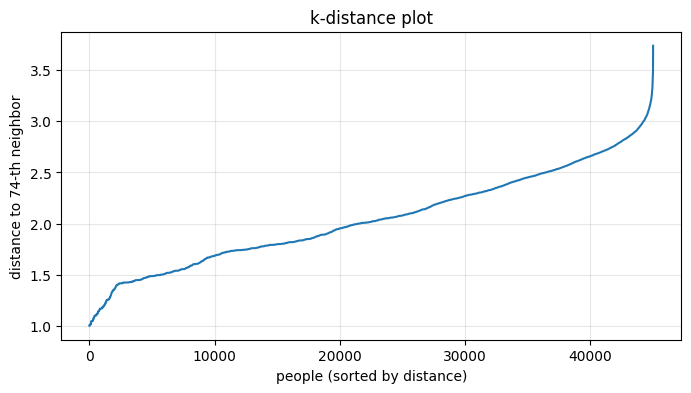

50% 的人在距離 2.02 以內
75% 的人在距離 2.40 以內
90% 的人在距離 2.68 以內
95% 的人在距離 2.82 以內
99% 的人在距離 3.07 以內


In [ ]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

prep_db = make_preprocessor()
Z = prep_db.fit_transform(X_t)
MIN_SAMPLES = 2 * Z.shape[1]
print(f"特徵數: {Z.shape[1]}, min_samples: {MIN_SAMPLES}")

nn_ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
dist, _ = nn_.kneighbors(Z)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.xlabel("people (sorted by distance)")
plt.ylabel(f"distance to {MIN_SAMPLES}-th neighbor")
plt.title("k-distance plot")
plt.grid(alpha=0.3)
plt.show()

for q in [50, 75, 90, 95, 99]:
    print(f"{q}% 的人在距離 {np.percentile(k_dist, q):.2f} 以內")

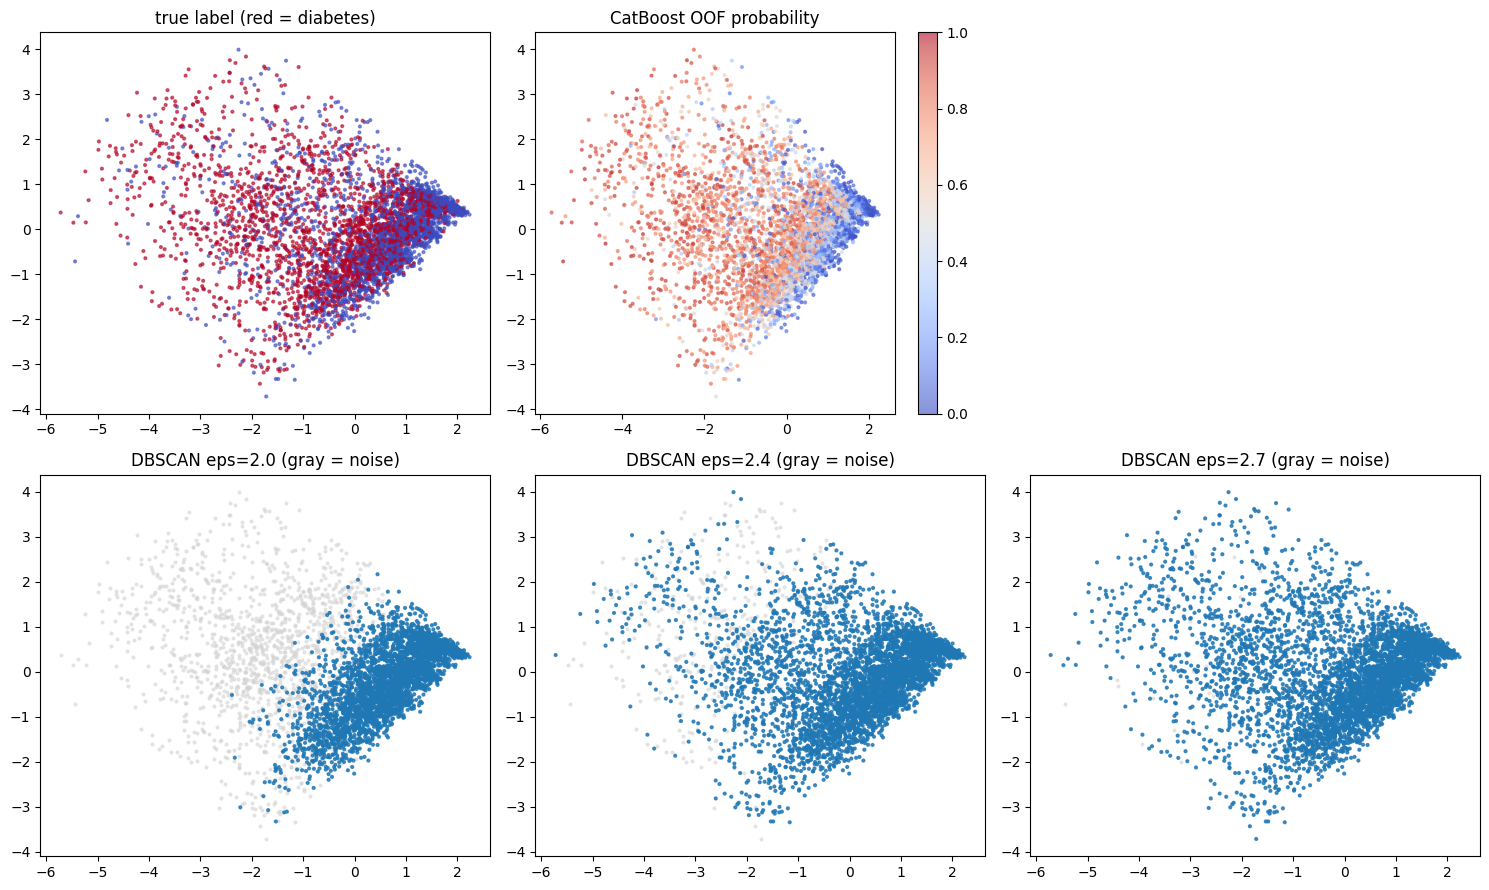


eps=2.0：最大的幾群（-1 是雜訊，mean 是糖尿病比例）
          size   mean
cluster              
 0       32354  0.428
-1       12712  0.683

eps=2.4：最大的幾群（-1 是雜訊，mean 是糖尿病比例）
          size   mean
cluster              
 0       42194  0.488
-1        2872  0.676

eps=2.7：最大的幾群（-1 是雜訊，mean 是糖尿病比例）
          size   mean
cluster              
 0       44896  0.499
-1         170  0.659


In [9]:
from sklearn.decomposition import PCA

rng = np.random.RandomState(RT)
idx = rng.choice(len(Z), size=5000, replace=False)
xy = PCA(n_components=2, random_state=RT).fit_transform(Z)[idx]

y_s = y_t.values[idx]
p_s = oof_cat.loc[X_t.index].values[idx]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

ax = axes[0, 0]
ax.scatter(xy[:, 0], xy[:, 1], c=y_s, cmap="coolwarm", s=4, alpha=0.6)
ax.set_title("true label (red = diabetes)")

ax = axes[0, 1]
sc = ax.scatter(xy[:, 0], xy[:, 1], c=p_s, cmap="coolwarm", s=4, alpha=0.6, vmin=0, vmax=1)
ax.set_title("CatBoost OOF probability")
fig.colorbar(sc, ax=ax)

axes[0, 2].axis("off")

for ax, (eps, labels) in zip(axes[1], db_labels.items()):
    lab = labels[idx]
    noise = lab == -1
    ax.scatter(xy[noise, 0], xy[noise, 1], c="lightgray", s=4, alpha=0.5)
    ax.scatter(xy[~noise, 0], xy[~noise, 1], c=lab[~noise] % 20, cmap="tab20", s=4, alpha=0.8)
    ax.set_title(f"DBSCAN eps={eps} (gray = noise)")

plt.tight_layout()
plt.show()

# 每個 eps 最大的幾群：人數和糖尿病比例
for eps, labels in db_labels.items():
    s = pd.DataFrame({"cluster": labels, "y": y_t.values})
    summary = s.groupby("cluster")["y"].agg(["size", "mean"]).sort_values("size", ascending=False)
    print(f"\neps={eps}：最大的幾群（-1 是雜訊，mean 是糖尿病比例）")
    print(summary.head(6).round(3))

In [10]:
base_cat = CatBoostClassifier(
    depth=6, iterations=600, l2_leaf_reg=10, learning_rate=0.03,
    random_seed=RT, verbose=0,
)
cv = StratifiedKFold(5, shuffle=True, random_state=RT)

for eps, labels in db_labels.items():
    X_db = X_t.copy()
    X_db["cluster"] = labels
    scores = cross_val_score(
        base_cat, X_db, y_t, cv=cv, scoring="accuracy",
        params={"cat_features": ["cluster"]},
    )
    print(f"eps={eps}: CatBoost + 群編號 CV = {scores.mean():.4f}")

print("原本的 CatBoost CV = 0.7572")

eps=2.0: CatBoost + 群編號 CV = 0.7572
eps=2.4: CatBoost + 群編號 CV = 0.7574
eps=2.7: CatBoost + 群編號 CV = 0.7579
原本的 CatBoost CV = 0.7572
